In [53]:
import sys
sys.path.append("/richmondvol1/rusty/stompy")

In [54]:
%matplotlib widget

In [55]:
import stompy.model.delft.dflow_model as dfm
import numpy as np
import stompy.model.hydro_model as hm
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from stompy import utils
import os
from stompy.plot import mkanim
from IPython import display 
from stompy import xr_transect

In [56]:
run_dir='bloom_tracers_v17/run_20220804T1820_20220905T0000_v00'

In [57]:
model = dfm.DFlowModel.load(run_dir)
map_ds = model.map_dataset(chain=False)

INFO:utils:1/16
INFO:utils:2/16
INFO:utils:3/16
INFO:utils:4/16
INFO:utils:5/16
INFO:utils:6/16
INFO:utils:7/16
INFO:utils:8/16
INFO:utils:9/16
INFO:utils:10/16
INFO:utils:11/16
INFO:utils:12/16
INFO:utils:13/16
INFO:utils:14/16
INFO:utils:15/16
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO

In [58]:
tidx=-1
if 0: # Sanity check on surface temperature field:
    scal = map_ds['tem1'].isel(time=tidx,laydim=-1).values
    
    fig,ax=plt.subplots(figsize=(9,7))
    ax.set_position([0,0,1,1])
    ax.axis('off')
    ax.set_adjustable('datalim')
    coll = map_ds.grid.plot_cells(ax=ax,values=scal,cmap='turbo',clim=[15,24],lw=0.5,ec='face')
    plt.colorbar(coll,label='Surface temperature (degC)')

In [59]:
# Get a vertical slice along this curve:
if 0:
    line = np.array( [  # Central Bay to San Mateo Bridge
        [552790,4.18799e6],
        [555200,4.1836e6],
        [558900,4.16994e6],
        [561290,4.16467e6],
        [566900,4.15954e6]] )
if 1:
    line = np.array( [  # Central Bay to Dumbarton Bridge
        [552790,4.18799e6],
        [555200,4.18360e6],
        [556620,4.17986e6],
        [558900,4.16994e6],
        [561290,4.16467e6],
        [564120,4.16179e6],
        [566900,4.15954e6],
        [568690,4.15852e6],
        [571000,4.15694e6],
        [573340,4.15451e6],
        [576780,4.15240e6],
        [577740,4.15135e6]
    ] )
if 0:
    line = np.array([[553950,4.1722e6],[567820,4.17356e6]]) # west to east, roughly Oakland airport
    
tidx=460

snap_ds = map_ds.isel(time=tidx).compute() # maybe faster to get one time step then slice it.
slice_ds=hm.extract_transect(snap_ds,line,map_ds.grid,include=['tem1','s1','FlowElem_bl'],dx=200)

INFO:multi_ugrid:Ragged shapes for NetElemNode, filling with 0
INFO:multi_ugrid:Ragged shapes for NetElemLink, filling with 0
INFO:multi_ugrid:Ragged shapes for FlowElemContour_x, filling with nan
INFO:multi_ugrid:Ragged shapes for FlowElemContour_y, filling with nan


INFO:multi_ugrid:Ragged shapes for NetElemNode, filling with 0
INFO:multi_ugrid:Ragged shapes for NetElemLink, filling with 0
INFO:multi_ugrid:Ragged shapes for FlowElemContour_x, filling with nan
INFO:multi_ugrid:Ragged shapes for FlowElemContour_y, filling with nan


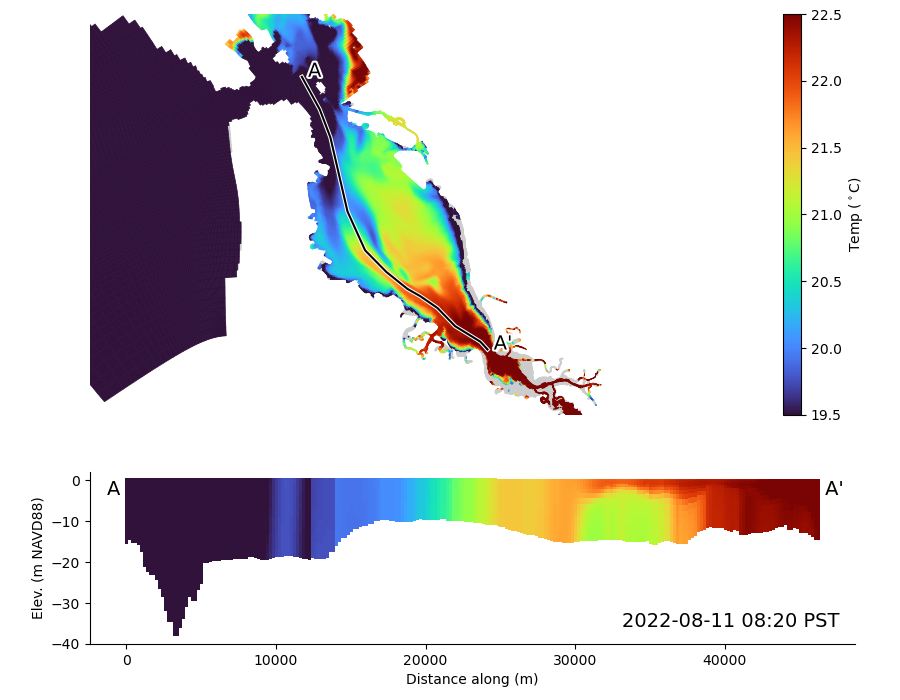

In [77]:
# Render in a time loop, and save images
buff=dict(path_effects=[pe.withStroke(linewidth=3, foreground="white")])
                    
fig,axs = plt.subplots(2,1,figsize=(9,7),height_ratios=[0.7,0.3])
fig.subplots_adjust(left=0.1,right=0.95,top=0.98,bottom=0.08)
pos = axs[0].get_position()
cax = fig.add_axes([0.87,pos.ymin,0.02,pos.height])
temp_clim=[19.5,22.5] 
ylim=[-40,2]
def update_tidx(tidx):
    for ax in axs:
        ax.cla()

    snap_ds = map_ds.isel(time=tidx).compute()
    slice_ds=hm.extract_transect(snap_ds,line,map_ds.grid,include=['tem1','s1','FlowElem_bl','waterdepth'],dx=200)
    
    ax=axs[0]
    # temperature in plan view:
    if 1:
        wet = snap_ds['waterdepth'].values >= 0.2
        map_ds.grid.plot_cells(mask=~wet,color='0.8',zorder=-1,ax=ax,ec='face')
    else:
        wet=None
    map_coll = map_ds.grid.plot_cells(values=snap_ds['tem1'].isel(laydim=-1).values,
                                      mask=wet,
                                      ax=ax,cmap='turbo',clim=temp_clim,lw=0.5,ec='face')
    ax.set_adjustable('datalim')
    ax.axis('off')
    ax.plot(slice_ds.x_sample,slice_ds.y_sample,'k-',**buff)
    ax.text(slice_ds.x_sample[0],slice_ds.y_sample[0],' A ',fontsize=14,**buff)
    ax.text(slice_ds.x_sample[-1],slice_ds.y_sample[-1]," A' ",fontsize=14,**buff)
    ax.axis((524319, 627117, 4142561, 4196434))
        
    ax=axs[1]
    artist = xr_transect.plot_scalar(slice_ds,'tem1',cmap='turbo',ax=ax,clim=temp_clim)
    ax.text(0,0,'A ',ha='right',va='top',fontsize=14)
    ax.text(slice_ds.d_sample.values[-1],0," A'",ha='left',va='top',fontsize=14)
    plt.colorbar(artist,ax=ax,label='Temp ($^\\circ$C)',cax=cax)
    ax.set_xlabel('Distance along (m)')
    ax.set_ylabel('Elev. (m NAVD88)')
    ax.set_ylim(ylim)
    ax.text(0.98,0.1,utils.strftime(snap_ds.time.values - np.timedelta64(8,'h')) +" PST",
            transform=ax.transAxes,ha='right', fontsize=14)
    ax.spines['top'].set_visible(0) ; ax.spines['right'].set_visible(0)

update_tidx(166)

In [46]:
img_patt=os.path.join(frame_dir,'temp_plan_and_slice-%04d.png')

In [47]:
frame_dir = "frames-v7-temp-slice"
if not os.path.exists(frame_dir):
    os.makedirs(frame_dir)

for tidx in range(map_ds.dims['time']):
    print(tidx)
    update_tidx(tidx)
    fig.savefig(img_patt%tidx)

INFO:multi_ugrid:Ragged shapes for NetElemNode, filling with 0
INFO:multi_ugrid:Ragged shapes for NetElemLink, filling with 0
INFO:multi_ugrid:Ragged shapes for FlowElemContour_x, filling with nan
INFO:multi_ugrid:Ragged shapes for FlowElemContour_y, filling with nan


0


INFO:multi_ugrid:Ragged shapes for NetElemNode, filling with 0
INFO:multi_ugrid:Ragged shapes for NetElemLink, filling with 0
INFO:multi_ugrid:Ragged shapes for FlowElemContour_x, filling with nan
INFO:multi_ugrid:Ragged shapes for FlowElemContour_y, filling with nan


1


INFO:multi_ugrid:Ragged shapes for NetElemNode, filling with 0
INFO:multi_ugrid:Ragged shapes for NetElemLink, filling with 0
INFO:multi_ugrid:Ragged shapes for FlowElemContour_x, filling with nan
INFO:multi_ugrid:Ragged shapes for FlowElemContour_y, filling with nan


...

748


INFO:multi_ugrid:Ragged shapes for NetElemNode, filling with 0
INFO:multi_ugrid:Ragged shapes for NetElemLink, filling with 0
INFO:multi_ugrid:Ragged shapes for FlowElemContour_x, filling with nan
INFO:multi_ugrid:Ragged shapes for FlowElemContour_y, filling with nan


749


INFO:multi_ugrid:Ragged shapes for NetElemNode, filling with 0
INFO:multi_ugrid:Ragged shapes for NetElemLink, filling with 0
INFO:multi_ugrid:Ragged shapes for FlowElemContour_x, filling with nan
INFO:multi_ugrid:Ragged shapes for FlowElemContour_y, filling with nan


750


In [49]:
anim_path=img_patt.replace("-%04d.png",".mp4")
mkanim.mkanim(out=anim_path, frame_path=img_patt, fps=6)

ffmpeg version 4.4.2-0ubuntu0.22.04.1 Copyright (c) 2000-2021 the FFmpeg developers
  built with gcc 11 (Ubuntu 11.2.0-19ubuntu1)
  configuration: --prefix=/usr --extra-version=0ubuntu0.22.04.1 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --enable-gnutls --enable-ladspa --enable-libaom --enable-libass --enable-libbluray --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libgme --enable-libgsm --enable-libjack --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-libpulse --enable-librabbitmq --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libsrt --enable-libssh --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enab

In [50]:
display.Video(anim_path)

In [52]:
os.path.abspath(anim_path)

'/richmondvol1/rusty/wy2022_bloom/frames-v7-temp-slice/temp_plan_and_slice.mp4'

INFO:multi_ugrid:Ragged shapes for NetElemNode, filling with 0
INFO:multi_ugrid:Ragged shapes for NetElemLink, filling with 0
INFO:multi_ugrid:Ragged shapes for FlowElemContour_x, filling with nan
INFO:multi_ugrid:Ragged shapes for FlowElemContour_y, filling with nan


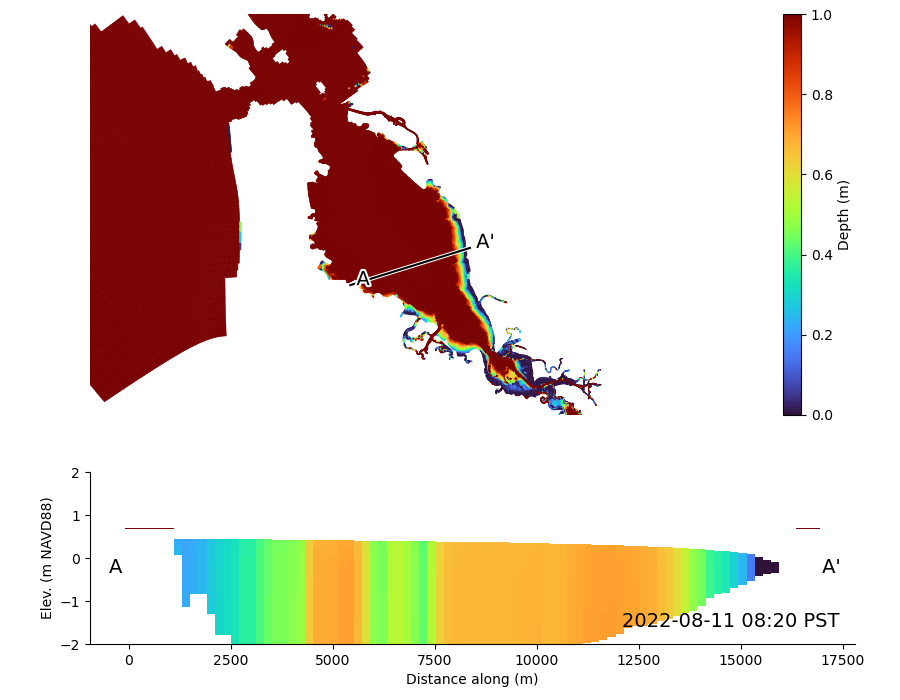

In [74]:
# Check depth
# 2022-08-11 8:20 PST

buff=dict(path_effects=[pe.withStroke(linewidth=3, foreground="white")])
                    
fig,axs = plt.subplots(2,1,figsize=(9,7),height_ratios=[0.7,0.3])
fig.subplots_adjust(left=0.1,right=0.95,top=0.98,bottom=0.08)
pos = axs[0].get_position()
cax = fig.add_axes([0.87,pos.ymin,0.02,pos.height])
temp_clim=[0,1.0] 
ylim=[-2,2]

line_across = np.array([[559300,4.1600e6],[575380,4.165e6]]) # west to east, roughly San Leandro

def update_tidx(tidx):
    for ax in axs:
        ax.cla()

    snap_ds = map_ds.isel(time=tidx).compute()
    slice_ds=hm.extract_transect(snap_ds,line_across,map_ds.grid,include=['tem1','s1','waterdepth','FlowElem_bl'],dx=200)
    
    ax=axs[0]
    # depth in plan view:
    map_coll = map_ds.grid.plot_cells(values=map_ds['waterdepth'].isel(time=tidx).values,
                                      ax=ax,cmap='turbo',clim=temp_clim,lw=0.5,ec='face')
    ax.set_adjustable('datalim')
    ax.axis('off')
    ax.plot(slice_ds.x_sample,slice_ds.y_sample,'k-',**buff)
    ax.text(slice_ds.x_sample[0],slice_ds.y_sample[0],' A ',fontsize=14,**buff)
    ax.text(slice_ds.x_sample[-1],slice_ds.y_sample[-1]," A' ",fontsize=14,**buff)
    ax.axis((524319, 627117, 4142561, 4196434))
    plt.colorbar(map_coll,ax=ax,label='Depth (m)',cax=cax)
        
    ax=axs[1]
    artist = xr_transect.plot_scalar(slice_ds,'tem1',cmap='turbo',ax=ax,clim=[19.5,22.5])
    ax.text(0,0,'A ',ha='right',va='top',fontsize=14)
    ax.text(slice_ds.d_sample.values[-1],0," A'",ha='left',va='top',fontsize=14)
    ax.set_xlabel('Distance along (m)')
    ax.set_ylabel('Elev. (m NAVD88)')
    ax.set_ylim(ylim)
    ax.text(0.98,0.1,utils.strftime(snap_ds.time.values - np.timedelta64(8,'h')) +" PST",
            transform=ax.transAxes,ha='right', fontsize=14)
    ax.spines['top'].set_visible(0) ; ax.spines['right'].set_visible(0)

update_tidx(166)

In [79]:
# plot time series of air temp and shoal temp.
c=map_ds.grid.select_cells_nearest([574794, 4.164432e6])

In [92]:
temp_ts = map_ds['tem1'].isel(laydim=-1, nFlowElem=c)

air_temp_ts = map_ds['Tair'].isel(nFlowElem=c)
depth_ts = map_ds['waterdepth'].isel(nFlowElem=c)

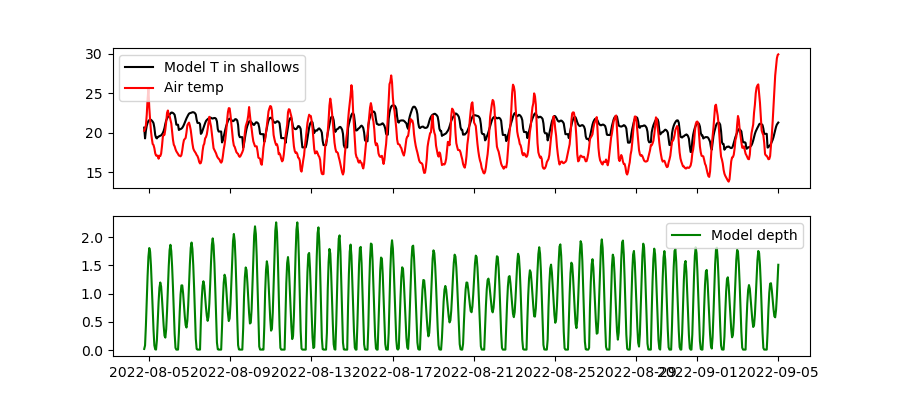

In [94]:
fig,axs=plt.subplots(2, 1, sharex=True, figsize=(9,4))

ax=axs[0]
ax.plot(temp_ts.time, temp_ts.values,'k-',label='Model T in shallows')
ax.plot(air_temp_ts.time, air_temp_ts.values,'r-',label='Air temp')

ax=axs[1]
ax.plot(depth_ts.time.values, depth_ts.values,'g',label='Model depth')

axs[0].legend()
axs[1].legend()

In [67]:
map_ds.dss[0]

<xarray.Dataset>
Dimensions:                      (nmesh2d_EnclosurePoints: 689,
                                  nmesh2d_EnclosureInstance: 1,
                                  nmesh2d_EnclosureParts: 1, nNetNode: 2883,
                                  nNetLink: 6354, nNetLinkPts: 2,
                                  nNetElem: 3472, nNetElemMaxNode: 6,
                                  nNetLinkContourPts: 4, nBndLink: 713,
                                  nFlowElem: 3472, nFlowElemContourPts: 6,
                                  nFlowLink: 5642, nFlowLinkPts: 2, time: 751,
                                  laydim: 16, wdim: 17)
Coordinates:
    NetNode_x                    (nNetNode) float64 5.809e+05 ... 5.816e+05
    NetNode_y                    (nNetNode) float64 4.151e+06 ... 4.153e+06
    FlowElem_xcc                 (nFlowElem) float64 5.809e+05 ... 5.873e+05
    FlowElem_ycc                 (nFlowElem) float64 4.151e+06 ... 4.149e+06
    FlowLink_xu                  (nFlowLink) float64 5.821e+05 ... 5.782e+05
    FlowLink_yu                  (nFlowLink) float64 4.154e+06 ... 4.147e+06
  * time                         (time) datetime64[ns] 2022-08-04T18:20:00 .....
    LayCoord_cc                  (laydim) float64 ...
    LayCoord_w                   (wdim) float64 ...
Dimensions without coordinates: nmesh2d_EnclosurePoints,
                                nmesh2d_EnclosureInstance,
                                nmesh2d_EnclosureParts, nNetNode, nNetLink,
                                nNetLinkPts, nNetElem, nNetElemMaxNode,
                                nNetLinkContourPts, nBndLink, nFlowElem,
                                nFlowElemContourPts, nFlowLink, nFlowLinkPts,
                                laydim, wdim
Data variables: (12/88)
    mesh2d_enc_x                 (nmesh2d_EnclosurePoints) float64 ...
    mesh2d_enc_y                 (nmesh2d_EnclosurePoints) float64 ...
    mesh2d_enc_node_count        (nmesh2d_EnclosureInstance) int32 ...
    mesh2d_enc_part_node_count   (nmesh2d_EnclosureParts) int32 ...
    mesh2d_enc_interior_ring     (nmesh2d_EnclosureParts) int32 ...
    mesh2d_enclosure_container   float32 ...
    ...                           ...
    vicwwu                       (time, nFlowLink, wdim) float64 ...
    tureps1                      (time, nFlowLink, wdim) float64 ...
    windx                        (time, nFlowElem) float64 ...
    windy                        (time, nFlowElem) float64 ...
    windxu                       (time, nFlowLink) float64 ...
    windyu                       (time, nFlowLink) float64 ...
Attributes:
    institution:    Deltares
    references:     http://www.deltares.nl
    source:         Deltares, D-Flow FM Version 1.2.167.141798M, Jun 09 2023,...
    history:        Created on 2025-08-17T09:39:51-0700, D-Flow FM
    date_created:   2025-08-17T09:39:51-0700
    date_modified:  2025-08-17T09:39:51-0700
    Conventions:    UGRID-0.9
    uuid:           e45b1583-b266-428c-9b21-e3e1da9b2fc6